## Names: Aeden Rask and Diego McGrath

## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

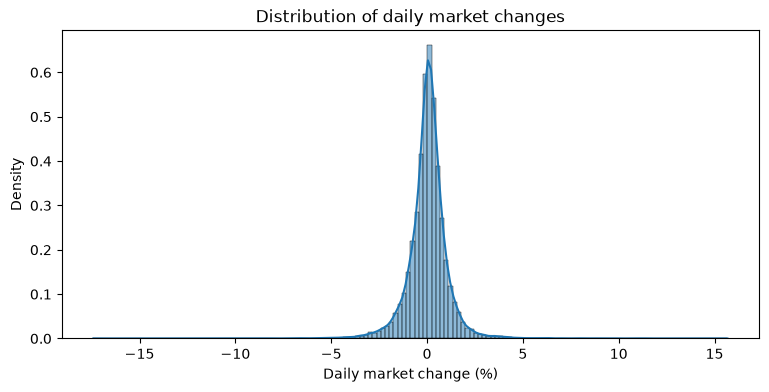

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

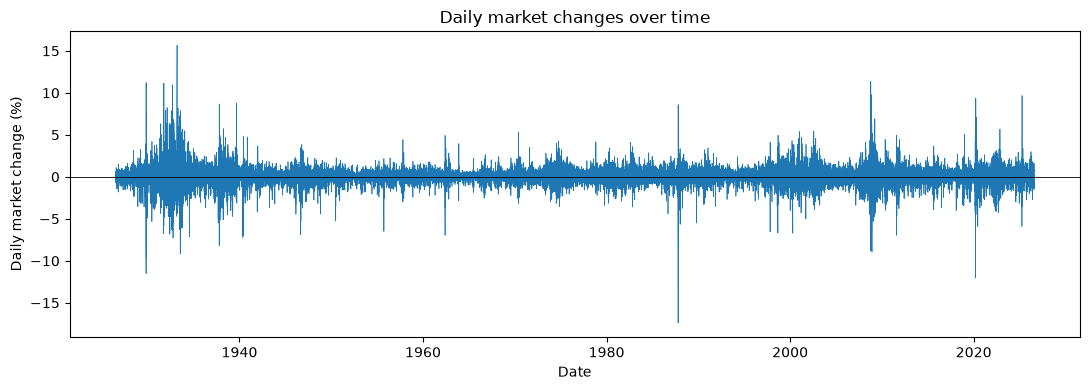

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
df['state'] = np.where(df['market_return_pct'] > 0, 'Up', 'Down')
df['next_state'] = df['state'].shift(-1)
pairs = df.dropna(subset=['next_state'])

joint = pd.crosstab(pairs['state'], pairs['next_state'], normalize='all')
marg_today = joint.sum(axis=1)
marg_next = joint.sum(axis=0)
cond = pd.crosstab(pairs['state'], pairs['next_state'], normalize='index')  # P(next | today)
print(joint)

next_state      Down        Up
state                         
Down        0.224720  0.228142
Up          0.228142  0.318996


Are up transitions more or less common than down transitions? 
- Up transitions are more common than Down transitions

In [5]:
print(cond)

next_state      Down        Up
state                         
Down        0.496221  0.503779
Up          0.416974  0.583026


<Axes: xlabel='next_state', ylabel='state'>

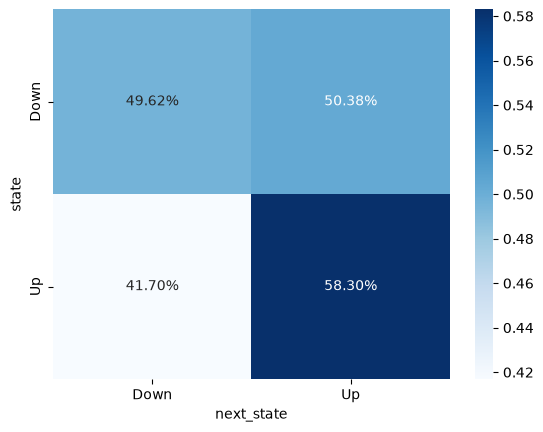

In [6]:
sns.heatmap(cond[['Down', 'Up']], annot=True, fmt='.2%', cmap='Blues')

Are you more likely to transition to an Up day from a Down or Up day?
- If the current state is Down, there is a 50.38% chance of the next state to be Up. If the current state is Up, there is a 58.30% chance of the next state to be Up. You are more likely to transition to an Up day from another Up day.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [7]:
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]

df['state'] = pd.cut(df['market_return_pct'], bins=bins, labels=labels)
df['next_state'] = df['state'].shift(-1)

counts = df['state'].value_counts().reindex(labels)
print(counts)

state
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64


How many days fall into each of the five bins? 
- Shown above

Which are the most or least common?
- The most common are small gain and small loss, and the least common are large loss, large gain, and near zero

<Axes: xlabel='next_state', ylabel='state'>

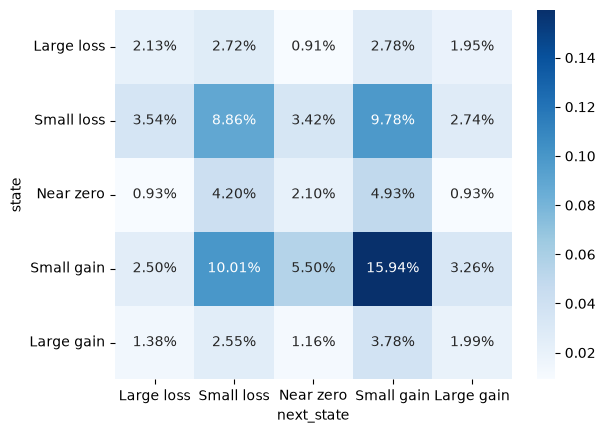

In [8]:
joint = (pd.crosstab(df['state'], df['next_state'], normalize='all')
           .reindex(index=labels, columns=labels))
sns.heatmap(joint, annot=True, fmt='.2%', cmap='Blues')

Which transitions are most likely to occur? 
- small gain to small gain, small gain to small loss, small loss to small gain, and small loss to small loss

<Axes: xlabel='next_state', ylabel='state'>

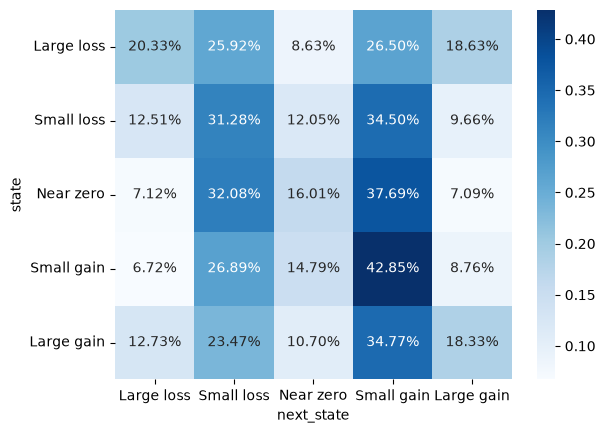

In [9]:
cond = (pd.crosstab(df['state'], df['next_state'], normalize='index')
          .reindex(index=labels, columns=labels))

sns.heatmap(cond, annot=True, fmt='.2%', cmap='Blues')

For each current state, which two future states are the most likely? 
- For all states, small loss and small gain are most likely.

Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- None of the rows are very uniform, but large loss seems to be the closest to uniform.

Is it relatively easy or difficult to predict the next state?
- The next bin is quite difficult to predict. The most likely next states have between a 27% and 43% chance of occurring.

In [10]:
df['next_return'] = df['market_return_pct'].shift(-1)
summary = df.groupby('state', observed=True)['next_return'].describe()
print(summary.round(2))

             count  mean   std    min   25%   50%   75%    max
state                                                         
Large loss  2759.0 -0.04  1.72 -17.41 -0.79 -0.01  0.72  11.22
Small loss  7452.0 -0.04  1.01 -11.23 -0.53  0.01  0.45  11.36
Near zero   3441.0  0.02  0.83  -8.19 -0.35  0.03  0.42   5.49
Small gain  9784.0  0.11  0.83  -8.25 -0.25  0.12  0.50   8.67
Large gain  2859.0  0.16  1.38 -12.00 -0.37  0.15  0.73  15.67


Given the current state, what are the expected percent returns for tomorrow? 
- Expected percents are shown above in the `mean` column. Tomorrow’s expected return rises as today’s state moves from losses to gains.

How do the min and max values for tomorrow vary across states? 
- Large loss has the most extreme min at -17.41%, followed by large gain at -12% and small loss at -11.23%. Near zero and small gain have similar means of -8.19% and -8.25% respectively.
- Large gain has the highest max of 15.67%. Then, small loss and large loss at slightly higher than 11%. small gain has a max of 8.67%, and near zero is the smallest at 5.49%

Which states have the highest standard deviation for tomorrow's percent returns? 
- Large loss has the highest standard deviation of 1.72, followed by Large gain at 1.38.

Describe any patterns in the volatility you notice.
- Volatility is highest after large moves in either direction. Large loss and Large gain have the two highest standard deviations, and Near zero and Small gain, the two smallest, both follow modest moves.
- Losses are more volatile than gains of the same size. Large loss (1.72) is well above Large gain (1.38), and Small loss (1.01) is above Small gain (0.83).

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [17]:
df['y_t'] = pd.qcut(df['market_return_pct'], 21, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts().sort_index()

y_t
0     1255
1     1253
2     1286
3     1280
4     1230
5     1226
6     1371
7     1206
8     1198
9     1331
10    1210
11    1223
12    1294
13    1223
14    1310
15    1193
16    1211
17    1283
18    1225
19    1250
20    1238
Name: count, dtype: int64

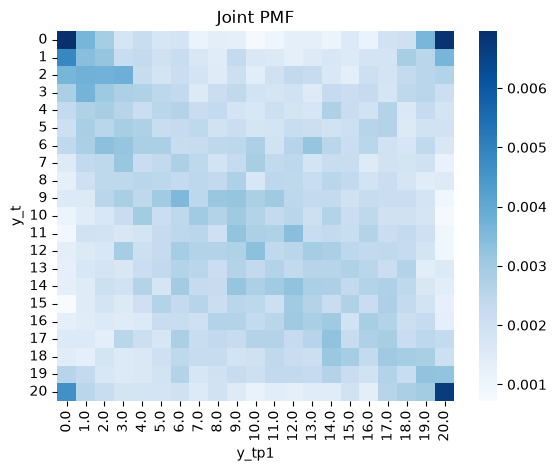

[Text(0.5, 1.0, 'Joint - Uniform')]

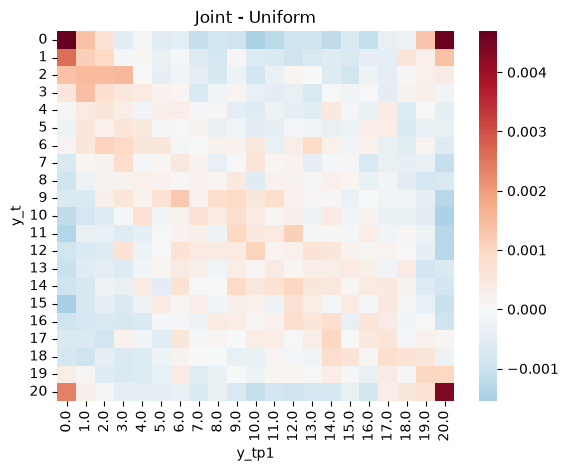

In [31]:
joint = pd.crosstab(df['y_t'], df['y_tp1'], normalize='all')

sns.heatmap(joint, cmap='Blues').set(title='Joint PMF')
plt.show()
sns.heatmap(joint - 1/21**2, cmap='RdBu_r', center=0).set(title='Joint - Uniform')

Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

Most of the plot, before subtracting 1/21** 2, is mostly flat, but the four corners show a clear distinction against the rest of the plot, and this is only more noticeable after subtracting the uniform PMF, where we can see the corners being bright red, suggesting that extreme days are often followed by extreme days. The light blue at the edges, not including the corners, suggests that extreme days are less often than random followed by calm days, but calm days are often followed by calm days as shown by the light red streak around the middle.

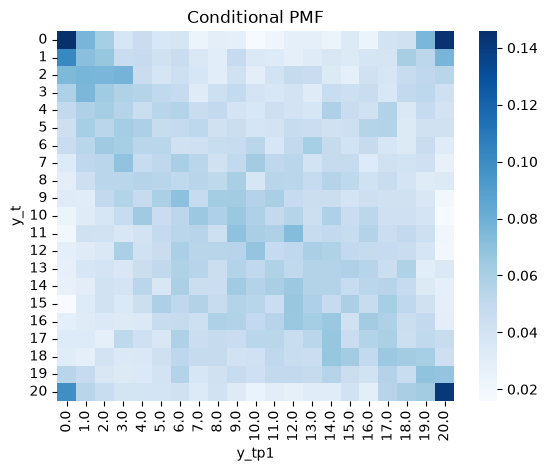

[Text(0.5, 1.0, 'Conditional - Uniform')]

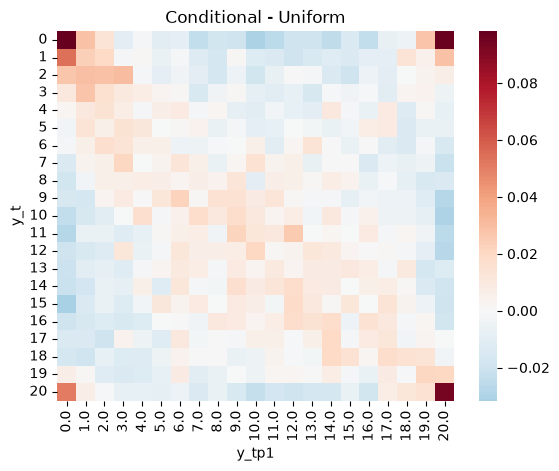

In [35]:
cond = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

sns.heatmap(cond, cmap='Blues').set(title='Conditional PMF')
plt.show()
sns.heatmap(cond - 1/21, cmap='RdBu_r', center=0).set(title='Conditional - Uniform')

Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.

Similar to the Joint PMF, we see a similar pattern in both the conditional PMF, and the conditional PMF minus the uniform. The corners show that there is a higher chance (~14%) that after an extreme day, another extreme day will follow, with lower chances for a calm day to follow an extreme day. Specifically, a crash day raises the chance of both another crash or large gain day. Furthermore, calm days are likely to follow calm days, as shown by the light red diagonal. 

      count  mean   std    min   25%   50%   75%    max
y_t                                                    
0    1255.0 -0.01  2.14 -17.41 -0.92 -0.02  0.90  11.22
1    1253.0 -0.08  1.29  -7.36 -0.74 -0.02  0.60   6.36
2    1286.0 -0.10  1.23  -8.79 -0.71 -0.03  0.47  11.36
3    1280.0 -0.06  1.05  -8.28 -0.58  0.00  0.49   6.16
4    1230.0 -0.02  0.99  -6.89 -0.47  0.02  0.47   4.56
5    1226.0 -0.02  1.02 -11.23 -0.50  0.02  0.50   6.37
6    1371.0 -0.03  0.93  -3.94 -0.50  0.03  0.41   7.37
7    1206.0 -0.01  0.84  -3.40 -0.42  0.03  0.41   4.76
8    1198.0  0.03  0.85  -6.00 -0.39  0.03  0.44   5.49
9    1331.0 -0.01  0.81  -8.19 -0.34  0.02  0.38   3.60
10   1210.0  0.03  0.81  -7.30 -0.30  0.06  0.43   4.69
11   1223.0  0.09  0.79  -8.25 -0.25  0.10  0.46   7.88
12   1294.0  0.06  0.78  -6.82 -0.28  0.08  0.45   5.66
13   1223.0  0.09  0.82  -5.12 -0.27  0.11  0.50   4.16
14   1310.0  0.09  0.83  -6.49 -0.25  0.12  0.49   5.70
15   1193.0  0.13  0.79  -6.99 -0.24  0.13  0.51

<Axes: title={'center': 'Next-day min/mean/max'}, xlabel='Today bin', ylabel='Next-day return (%)'>

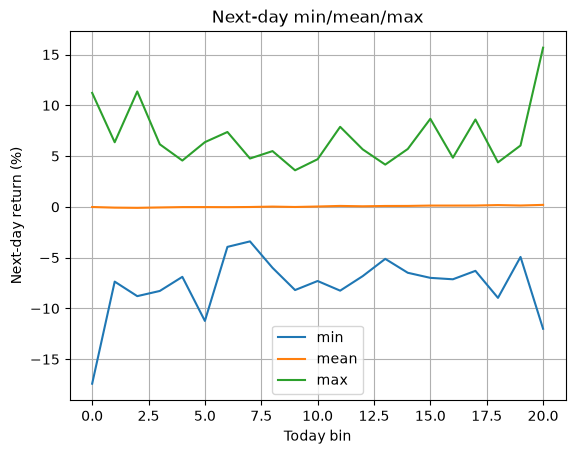

In [28]:
summary = df.groupby('y_t')['next_return'].describe()
print(summary.round(2))

summary[['min', 'mean', 'max']].plot(xlabel='Today bin', 
                                     ylabel='Next-day return (%)',
                                     title='Next-day min/mean/max',
                                     grid=True)

For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 

The mean is centered around 0, with the min and max flaring out at the ends. After bin 0, they are -17.4% and +11.2%, and after bin 20, they are -12.0% and +15.7%. With the middle bins, we see a much narrower range. This funnel-like shape reflects the volatility pattern we have seen in the previous parts, where extreme days tend to follow extreme days. 

<Axes: title={'center': "Next-day volatility by today's bin"}, xlabel='Today bin', ylabel='Next-day std (%)'>

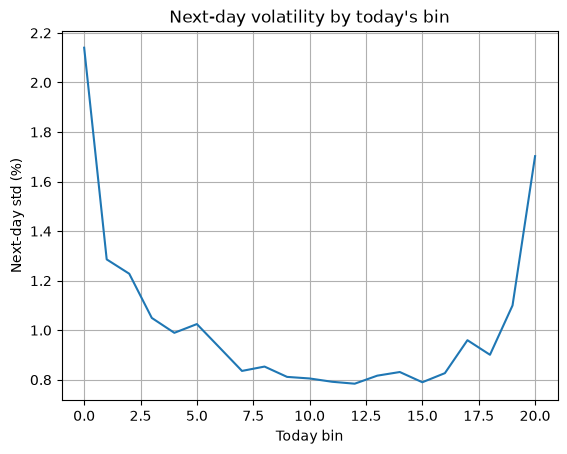

In [29]:
summary['std'].plot(xlabel='Today bin', 
                    ylabel='Next-day std (%)',
                    title='Next-day volatility by today\'s bin',
                    grid=True)

For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain.

The plot is U-shaped that, again, shows the same pattern we have been seeing previously, where volatile days follow volatile days. The loss side is higher compared to the gain side (2.14 compared to 1.70), suggesting that large drops lead to even more turbulence than big gains. The middle bins are generally centered around 0.8.

How easy is it to predict the market?

Predicting the market is not very easy, as we cannot easily predict the direction of the market. We showed in the conditional and joint PMF heatmaps that volatile days tend to follow volatile days, but predicting the direction of the market, whether an increase or decrease for the next day, remains much more difficult. It is much easier to predict the volatility of the market, as a large drop or gain is likely to be followed by a large movement, but predicting whether that large movement is a gain or a loss is not as easy, as shown by the next day mean being nearly 0 across all bins.